## How to use this notebook

**Requirements:** `data/ks-projects-201801.csv` (main data) and, optionally, `data/ks-projects-201612.csv` (only for the snapshot comparison in section 2; skipped if missing).

**Run it:** *Restart Kernel → Run All*. Cells depend on each other (e.g. `target_state` is created in section 14 and used from section 16 on), so always run them top to bottom.

**`RUN_MODEL_CHECKS`** (setup cell) switches the cells that train quick models (sections 4b, 10b and 21b):
- `True`: full evidence, takes a few extra minutes.
- `False`: fast run. The model checks are skipped, but all the cleaning, the charts and the saved file are exactly the same.

**`ONE_HOT_ENCODE`** (setup cell) sets how the 6 categorical features (`launch_weekday`, `launch_month`, `launch_day`, `launch_hour`, `country`, `category`) are saved (section 20):
- `True`: one-hot, one 0/1 column per value (e.g. `launch_hour_0` ... `launch_hour_23`). Ready for any model.
- `False`: one column per feature (weekday, country and category as text; month, day and hour as numbers). Encode them in the modelling step, or pass them as pandas `category` to a model that handles them (e.g. `HistGradientBoostingClassifier`).

The other switches in the setup cell (`CANCELED_KEEP_AS_FAIL_BELOW`, `DROP_SUSPENDED`, `DROP_FLAGS`, `RARE_SHARE`, `REPOST_DAYS`) change the cleaning decisions. Re-run everything after changing them.

**Output:** `data/kickstarter_final.csv`, 366,690 rows × 146 columns (`ONE_HOT_ENCODE = True`) or × 14 columns (`False`):
- `target_state`: what to predict (1 = successful, 0 = failed, or canceled with less than 50% of the goal; success rate 36.4%).
- 5 numeric features (`log10_goal_usd`, `name_length`, `duration_days`, `launch_year`, `goal_vs_category`) + the 6 categorical features (138 one-hot columns, or 6 single columns).
- `split_group` and `original_state`: **not features**. Drop them before training; `original_state` is the outcome itself.

**Using the output for modelling:**
- Split train/test by `split_group` (`GroupShuffleSplit` / `StratifiedGroupKFold`), so relaunches of the same project never sit on both sides.
- Accuracy alone is misleading: always predicting "fail" already gives 63.6%. Report ROC-AUC, F1 or precision/recall.

**Main findings and decisions**
- Live projects removed: even the 441 already funded have no final outcome.
- "(Canceled)" / "(Suspended)" labels are stripped from names before computing `name_length` (they leak the outcome).
- Goal on a log scale, no capping: success falls steadily from ~79% (under $10) to 0% ($10M+). It is likely one of the strongest features.
- Duration left as it is: success depends on the exact value (30 days: 32%, 60 days: 19%), not a smooth trend.
- Weekday has little effect; launch hour has a moderate one (peak ~44% around 15:00, probably UTC).
- Relaunched projects are kept: removing them does not change the model score (AUC ~0.756 one-hot, ~0.759 without).

Sections 7, 14, 16, 21 and 21b have a short markdown explanation of their results below them; the other cells explain their result in the comments at the top.

# Kickstarter: EDA, checks and preprocessing

**Goal:** prepare `ks-projects-201801.csv` for a model that predicts, **at launch time**, whether a Kickstarter
project will be funded.

This file contains every check we ran, the evidence behind each decision, and the preprocessing itself.

**Decisions (summary)**
1. Dataset: `ks-projects-201801.csv` (the 2016 file is an older snapshot of the same projects).
2. Columns excluded: `ID`, `name`, `main_category`, `currency`, `goal`, `pledged`, `backers`, `usd pledged`,
   `usd_pledged_real` (+ the raw dates once their features exist).
3. New features: name length (without the "(Canceled)" / "(Suspended)" labels), campaign duration and
   `goal_vs_category` (the goal compared with the typical goal of its category, section 21c).
4. Launch date → year (numeric), month, day, weekday and hour (categorical).
5. `country` and `category`: values below 0.5% of rows grouped into "Other". All 6 categorical features are one-hot
   encoded when `ONE_HOT_ENCODE = True`, otherwise kept as one column each.
6. `currency` dropped: it is fully explained by `country`.
7. Rows with missing values removed.
8. Target `state` → 1 = successful, 0 = failed; canceled split into 3 groups (see the canceled cells);
   suspended dropped; live and undefined dropped.
9. Joke / test projects flagged and the clear ones dropped (see the flagging cells).
10. Goal on a log scale (`log10_goal_usd`), no capping; duration left as it is.
11. Same project re-posted within 7 days: only the last posting kept; later relaunches kept and linked by
    `split_group` (use it for a grouped train/test split, never as a feature).

In [1]:
# Setup: libraries, file paths and switches
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, skew

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 70)

import matplotlib.pyplot as plt

# chart style: one blue for data, grey ink for text, light grid behind the data
BLUE, INK, MUTED, GRID = "#2a78d6", "#52514e", "#8a8984", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": GRID, "axes.labelcolor": INK, "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK, "ytick.color": INK,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "font.size": 9,
    "text.parse_math": False,                                             # "$" in labels is text, not math
})

DATA = "data/ks-projects-201801.csv"
OLD_DATA = "data/ks-projects-201612.csv"      # optional: only used in the snapshot-comparison cell
OUTPUT = "data/kickstarter_final.csv"

RARE_SHARE = 0.005                      # category / country values below 0.5% of rows -> "Other"
REPOST_DAYS = 7                         # same project posted again within 7 days = a re-post, not a new attempt
RUN_MODEL_CHECKS = True                 # cells that train a quick model (about 1-2 minutes in total)
ONE_HOT_ENCODE = False                   # True: one-hot category, country, weekday, launch month / day / hour; False: one column each

# decisions that can be switched
CANCELED_KEEP_AS_FAIL_BELOW = 0.5       # canceled with < 50% of the goal pledged -> failed; the rest dropped
DROP_SUSPENDED = True                   # suspended = Kickstarter's decision, not a funding outcome
DROP_FLAGS = ["potato_salad_wave", "test_project", "silly_tiny_goal"]   # flags whose projects are dropped

decision_log = []                       # every step that removes rows is recorded here


def log_step(text, before, after):
    decision_log.append((text, before - after, after))
    print(f"{text}: {before - after:,} rows removed, {after:,} left")

In [2]:
# 1. Load the data and take a first look
raw = pd.read_csv(DATA, low_memory=False)
#raw2 = pd.read_csv(OLD_DATA, low_memory=False)
print(raw.shape)
print(raw.dtypes)
raw.head()

(378661, 15)
ID                    int64
name                    str
category                str
main_category           str
currency                str
deadline                str
goal                float64
launched                str
pledged             float64
state                   str
backers               int64
country                 str
usd pledged         float64
usd_pledged_real    float64
usd_goal_real       float64
dtype: object


,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhood Filmmaking,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


In [3]:
# 1b. Standardise column names (snake_case) and parse the dates
df = raw.copy()
df.columns = df.columns.str.strip().str.lower().str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_") #create consisten names 
df["launched_dt"] = pd.to_datetime(df["launched"])
df["deadline_dt"] = pd.to_datetime(df["deadline"])
df["pct_funded"] = df["usd_pledged_real"] / df["usd_goal_real"]   # for checks only, NEVER a feature
print(list(df.columns))

['id', 'name', 'category', 'main_category', 'currency', 'deadline', 'goal', 'launched', 'pledged', 'state', 'backers', 'country', 'usd_pledged', 'usd_pledged_real', 'usd_goal_real', 'launched_dt', 'deadline_dt', 'pct_funded']


In [4]:
# 2. Optional: is the 2016 file a different dataset? (snapshot comparison)
# Result found: the 2018 file contains all 323,750 projects of the 2016 file plus 54,911 projects launched later.
# Shared projects agree ~99.8% (projects still "live" in 2016 got their final state; the deadline lost its time part).
# The 2016 file also has 616 rows shifted by unquoted commas and a Windows-1252 encoding -> we use the 2018 file only.
try:
    old = pd.read_csv(OLD_DATA, encoding="cp1252", encoding_errors="replace", low_memory=False)
    old.columns = old.columns.str.strip()
    old_ids, new_ids = set(pd.to_numeric(old["ID"], errors="coerce").dropna().astype("int64")), set(raw["ID"])
    print(f"2016 projects also in 2018: {len(old_ids & new_ids):,} of {len(old_ids):,}; "
          f"new in 2018: {len(new_ids - old_ids):,}")
except FileNotFoundError:
    print(f"{OLD_DATA} not found: comparison skipped")

2016 projects also in 2018: 323,750 of 323,750; new in 2018: 54,911


In [5]:
# 3. Target: which states exist?
print(df["state"].value_counts())
print(df["state"].value_counts(normalize=True).round(3)) #percentage

state
failed        197719
successful    133956
canceled       38779
undefined       3562
live            2799
suspended       1846
Name: count, dtype: int64
state
failed        0.522
successful    0.354
canceled      0.102
undefined     0.009
live          0.007
suspended     0.005
Name: proportion, dtype: float64


In [6]:
# 4. Leakage check: pledged, backers, usd_pledged, usd_pledged_real are campaign RESULTS
# They are only known after the campaign. Evidence:
#  - "pledged >= goal" matches "successful" for ~100% (99.997%) of finished projects (that is how success is defined)
#  - projects with 0 backers succeed 0.3% of the time
#  - (2016 vs 2018 files) for projects still live in 2016, pledged grew for 71% and backers for 68% by 2018
fin = df[df["state"].isin(["successful", "failed"])]
print("pledged >= goal  <->  successful:", ((fin["pct_funded"] >= 1) == (fin["state"] == "successful")).mean())
print("success rate with 0 backers:", (fin.loc[fin["backers"] == 0, "state"] == "successful").mean().round(4))

pledged >= goal  <->  successful: 0.9999668350041456
success rate with 0 backers: 0.0027


In [7]:
# 4b. Leakage check with a quick model: too good to be true
# AUC 0.5 = guessing, 1.0 = perfect. Goal + duration alone ~0.67; adding backers or pledged jumps to ~0.98-1.0.
if RUN_MODEL_CHECKS:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import train_test_split

    s = fin.sample(100_000, random_state=0)
    y = (s["state"] == "successful").astype(int)
    base = pd.DataFrame({"log_goal": np.log10(s["usd_goal_real"]),
                         "duration": (s["deadline_dt"] - s["launched_dt"].dt.normalize()).dt.days})
    for label, X in [("goal + duration", base), ("+ backers", base.assign(b=s["backers"])),
                     ("+ usd_pledged_real", base.assign(p=s["usd_pledged_real"]))]:
        tr, te, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
        m = HistGradientBoostingClassifier(max_iter=200, random_state=0).fit(tr, ytr)
        print(f"{label:22s} AUC = {roc_auc_score(yte, m.predict_proba(te)[:, 1]):.4f}")

goal + duration        AUC = 0.6696
+ backers              AUC = 0.9786
+ usd_pledged_real     AUC = 0.9999


In [8]:
# 5. Money columns: goal vs usd_goal_real, usd_pledged vs usd_pledged_real
# goal is in the project's own currency -> not comparable across countries; usd_goal_real is the same goal in USD
# (identical to goal for USD projects). usd_pledged is Kickstarter's own conversion: it differs from the corrected
# usd_pledged_real for ~56% of non-USD projects and is missing for 3,797 rows. Both pledged columns are leakage anyway.
usd = df[df["currency"] == "USD"]
print("goal == usd_goal_real for USD projects:", (usd["goal"] == usd["usd_goal_real"]).mean())
non_usd = df[(df["currency"] != "USD") & df["usd_pledged"].notna()]
print("usd_pledged differs from usd_pledged_real (non-USD, >1%):",
      ((non_usd["usd_pledged"] - non_usd["usd_pledged_real"]).abs() > 0.01 * non_usd["usd_pledged_real"] + 1).mean().round(3))
print("usd_pledged missing:", df["usd_pledged"].isna().sum())

goal == usd_goal_real for USD projects: 1.0
usd_pledged differs from usd_pledged_real (non-USD, >1%): 0.563
usd_pledged missing: 3797


In [9]:
# 6. Currency is explained by country -> drop currency
# Cramer's V ~ 1.0 (0.995) between the two; within each currency (except EUR, shared by several countries) one
# country covers ~98-100% of projects.
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))


print("Cramer's V currency ~ country:", round(cramers_v(df["currency"], df["country"]), 3))
print(df.groupby("currency")["country"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).round(3))

Cramer's V currency ~ country: 0.995
currency
AUD    0.986
CAD    0.986
CHF    0.991
DKK    0.986
EUR    0.240
GBP    0.987
HKD    1.000
JPY    1.000
MXN    1.000
NOK    0.981
NZD    0.981
SEK    0.983
SGD    1.000
USD    0.991
Name: country, dtype: float64


In [10]:
# 7. Remove live and undefined projects (no known outcome)
# live: campaign not finished. undefined: outcome unknown (all of them also carry the broken country code 'N,0"').
n = len(df)
df = df[~df["state"].isin(["live", "undefined"])].copy()
log_step("live / undefined removed", n, len(df))

live / undefined removed: 6,361 rows removed, 372,300 left


### Why all live projects are removed (even the ones already funded)

A live project has not finished yet, so its final outcome is unknown. What we *can* check is which ones had **already reached their goal** when the data was collected: Kickstarter is all-or-nothing, so a project at or above its goal at the deadline is successful. These are very likely future successes (backers can still withdraw pledges, so it is not 100% certain).

In the 2018 file, **441 of the 2,799 live projects (15.8%) were already at or above their goal.**

We still remove all of them:
- **The other 84% have no outcome.** Many of them will still reach their goal before the deadline, so calling them "failed" would mislabel them.
- **Keeping only the 441 funded ones would skew the data.** It adds live projects that will succeed but none that will fail, which pushes the success rate up a little.
- **The 2016 file cannot help.** These projects were live in early 2018, so they launched after the 2016 snapshot was taken.

One more warning sign: some "live" projects have deadlines as early as **May 2016**. Data collected in January 2018 should not show them as live, so their state is probably stale. That is another reason not to trust the `live` label.

In [11]:
# 8. Missing values and placeholders
# Real gaps: name (4 rows) and usd_pledged (dropped column, irrelevant). Placeholders: country 'N,0"' and launch
# dates of 1970-01-01 (unknown). Rows with missing values in the columns we use are removed.
df["country"] = df["country"].replace('N,0"', np.nan)
df.loc[df["launched_dt"].dt.year < 2000, "launched_dt"] = pd.NaT
used = ["name", "category", "country", "usd_goal_real", "launched_dt", "deadline_dt", "state"]
print(df[used].isna().sum())
n = len(df)
df = df.dropna(subset=used).copy()
log_step("rows with missing values removed (name, country 'N,0\"', launch date 1970)", n, len(df))

name               4
category           0
country          234
usd_goal_real      0
launched_dt        7
deadline_dt        0
state              0
dtype: int64
rows with missing values removed (name, country 'N,0"', launch date 1970): 245 rows removed, 372,055 left


In [12]:
# 9. Names: Kickstarter adds "(Canceled)" / "(Suspended)" to the name AFTER the fact
# The label sits inside the name itself (e.g. "Blankillow (Canceled)", "DogDanner™ (Suspended)"). Counting name length
# with it would leak the outcome (+11/+12 characters = canceled/suspended), and it was added for 74-100% of
# projects launched 2009-2015 but 0% in 2017 -> always strip it before using the name.
label = df["name"].str.contains(r"\((?:Canceled|Suspended)\)")
print("names with a (Canceled)/(Suspended) label:", label.sum())
print(df[df["state"] == "canceled"].groupby(df["launched_dt"].dt.year)["name"]
      .apply(lambda s: s.str.contains(r"\(Canceled\)").mean()).round(2))
df["name_clean"] = df["name"].str.replace(r"(\s*\((?:Canceled|Suspended)\))+\s*$", "", regex=True).str.strip()

names with a (Canceled)/(Suspended) label: 24133
launched_dt
2009    1.00
2010    0.93
2011    0.77
2012    0.81
2013    0.74
2014    0.78
2015    0.78
2016    0.39
2017    0.00
2018    0.00
Name: name, dtype: float64


In [13]:
# 10. Canceled projects: what are they?
# No cancellation date exists, but we know (a) how much was pledged when they cancelled and (b) what they looked like
# at launch. 76% had < 10% of their goal; 1.8% had already reached it.
canc = df[df["state"] == "canceled"]
bands = [-0.001, 0, 0.1, 0.25, 0.5, 1 - 1e-9, np.inf]
labels = ["0%", "0-10%", "10-25%", "25-50%", "50-99%", ">=100%"]
print(pd.DataFrame({
    "canceled": pd.cut(canc["pct_funded"], bands, labels=labels).value_counts(normalize=True).reindex(labels).round(3),
    "failed": pd.cut(df.loc[df["state"] == "failed", "pct_funded"], bands, labels=labels)
              .value_counts(normalize=True).reindex(labels).round(3)}))

            canceled  failed
pct_funded                  
0%             0.310   0.196
0-10%          0.452   0.536
10-25%         0.117   0.143
25-50%         0.068   0.091
50-99%         0.035   0.034
>=100%         0.018   0.000


In [14]:
# 10b. Canceled at launch: do they look like failed or successful projects? (model check)
# A model trained ONLY on successful vs failed with launch-time information scores canceled projects like failed
# ones (~32% vs failed 32%, successful 53%). Canceled projects that had already reached their goal look like
# successful ones (~53%).
if RUN_MODEL_CHECKS:
    from sklearn.model_selection import StratifiedKFold, cross_val_predict

    X = pd.DataFrame({
        "log_goal": np.log10(df["usd_goal_real"]),
        "duration": (df["deadline_dt"] - df["launched_dt"].dt.normalize()).dt.days,
        "year": df["launched_dt"].dt.year, "month": df["launched_dt"].dt.month,
        "weekday": df["launched_dt"].dt.weekday, "hour": df["launched_dt"].dt.hour,
        "name_len": df["name_clean"].str.len(),
        "category": df["category"].astype("category").cat.codes, "country": df["country"].astype("category").cat.codes})
    fs = df["state"].isin(["failed", "successful"])
    yy = (df["state"] == "successful").astype(int)
    m = HistGradientBoostingClassifier(max_iter=300, categorical_features=[7, 8], random_state=0)
    p = pd.Series(np.nan, index=df.index)
    p[fs] = cross_val_predict(m, X[fs], yy[fs], cv=StratifiedKFold(5, shuffle=True, random_state=0),
                              method="predict_proba")[:, 1]
    p[~fs] = m.fit(X[fs], yy[fs]).predict_proba(X[~fs])[:, 1]
    print("average predicted chance of success at launch:\n", p.groupby(df["state"]).mean().round(3))
    print("canceled, by funding at cancellation:\n",
          p[df["state"] == "canceled"].groupby(pd.cut(canc["pct_funded"], bands, labels=labels), observed=False).mean().round(3))

average predicted chance of success at launch:
 state
canceled      0.325
failed        0.321
successful    0.526
suspended     0.339
dtype: float64
canceled, by funding at cancellation:
 pct_funded
0%        0.280
0-10%     0.295
10-25%    0.409
25-50%    0.456
50-99%    0.484
>=100%    0.529
dtype: float64


In [15]:
# 10c. Canceled projects that were relaunched later
# 4.5% of canceled projects are posted again later (failed: 0.5%); 618 of those relaunches succeeded. Cancel-and-
# relaunch is a strategy: pull a weak campaign, come back with a better one. Quick re-posts (<= 7 days) are removed in
# the duplicates cell; later relaunches stay as their own rows (linked by split_group).
key = df["name_clean"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
df["family"] = np.where(key.str.len() >= 6, key + "|" + df["category"], "row" + df["id"].astype(str))
df = df.sort_values("launched_dt")
nxt = df.groupby("family")["state"].shift(-1)
c = df["state"] == "canceled"
print("canceled later relaunched:", int((c & nxt.notna()).sum()), "| relaunch outcome:", nxt[c].value_counts().to_dict())

canceled later relaunched: 1729 | relaunch outcome: {'failed': 808, 'successful': 618, 'canceled': 293, 'suspended': 10}


## Decision: canceled projects (38,773 in the file)

| Group | Treatment | Why |
|---|---|---|
| Canceled with **under 50%** of the goal pledged (~95%) | **failed (0)** | looked like failures at launch and were clearly heading there |
| Canceled at **50–99%** | **dropped** | could have gone either way; the outcome is unknown |
| Canceled **after reaching the goal** | **dropped** | backers funded it; the creator stopped for other reasons, so neither a fail nor a success |

Result on this file (after removing rows with missing values): 38,751 canceled → **36,696 kept as failed**,
**2,055 dropped** (1,358 at 50–99% of the goal + 697 that had reached it).

The pledged amount is only used to decide which label is trustworthy; it never becomes a feature.
Dropping all canceled projects instead would remove ~36,700 genuine near-failures and make the model over-optimistic.

In [16]:
# 10d. Apply the canceled decision (counts are printed)
canc_idx = df.index[df["state"] == "canceled"]
keep_fail = df.loc[canc_idx, "pct_funded"] < CANCELED_KEEP_AS_FAIL_BELOW
mid = (df.loc[canc_idx, "pct_funded"] >= CANCELED_KEEP_AS_FAIL_BELOW) & (df.loc[canc_idx, "pct_funded"] < 1)
funded = df.loc[canc_idx, "pct_funded"] >= 1
print(f"canceled projects: {len(canc_idx):,}")
print(f"  kept as failed (< {CANCELED_KEEP_AS_FAIL_BELOW:.0%} funded): {int(keep_fail.sum()):,}")
print(f"  dropped, {CANCELED_KEEP_AS_FAIL_BELOW:.0%}-99% funded (outcome uncertain): {int(mid.sum()):,}")
print(f"  dropped, had reached the goal (not a failure): {int(funded.sum()):,}")
n = len(df)
df = df.drop(index=canc_idx[~keep_fail.values])
log_step("canceled projects with >= 50% of the goal removed", n, len(df))

canceled projects: 38,751
  kept as failed (< 50% funded): 36,696
  dropped, 50%-99% funded (outcome uncertain): 1,358
  dropped, had reached the goal (not a failure): 697
canceled projects with >= 50% of the goal removed: 2,055 rows removed, 370,000 left


In [17]:
# 11. Suspended projects: what are they?
# Kickstarter stops a project when it breaks its rules (no working prototype, misleading claims, suspected fraud,
# prohibited items, personal fundraising). Famous examples in this file: Kobe Red beef jerky (2013, $120k raised on a
# $2,374 goal, suspected fraud) and the Skarp Laser Razor (2015, $4.0M on $160k, no working prototype).
# 292 of 1,846 had already passed their goal; 616 had no backers -> the suspension is Kickstarter's decision, not a
# funding outcome.
susp = df[df["state"] == "suspended"]
print(f"suspended: {len(susp):,} | reached goal: {(susp['pct_funded'] >= 1).sum():,} | 0 backers: {(susp['backers'] == 0).sum():,}")
print(susp.sort_values("usd_pledged_real", ascending=False)[["name", "usd_goal_real", "usd_pledged_real", "backers"]].head(5))

suspended: 1,842 | reached goal: 292 | 0 backers: 612
                                                               name  usd_goal_real  usd_pledged_real  backers
264291      The Skarp Laser Razor: 21st Century Shaving (Suspended)       160000.0        4005111.42    20632
114691                 anonabox : a Tor hardware router (Suspended)         7500.0         585549.35     8928
283466     iFind - The World's First Battery-Free Item Locating Tag        25000.0         546852.41     9771
141092  Firestarter Survival Bracelet / Carabiner Paracord Keychain        10000.0         477462.00     9139
84248    73 Year Old Watchmaker Launches NEWEST Watch With Grandson        10000.0         424687.20     5881


In [18]:
# 11b. Apply the suspended decision
if DROP_SUSPENDED:
    n = len(df)
    df = df[df["state"] != "suspended"].copy()
    log_step("suspended projects removed", n, len(df))

suspended projects removed: 1,842 rows removed, 368,158 left


In [19]:
# 12. Duplicates (1): exact duplicate records
# No two rows share an ID, and no two rows share name + launch time.
print("duplicate IDs:", df["id"].duplicated().sum())
print("same name + launch time:", df.duplicated(["name", "launched"]).sum())

duplicate IDs: 0
same name + launch time: 0


In [20]:
# 12b. Duplicates (2): the same project posted more than once
# Same cleaned name in the same category. Posted again within 7 days = the first posting was an aborted draft
# (typically canceled after ~44 hours and re-posted, 73% with a new goal) -> keep only the last posting.
# Posted again later = a real new attempt (relaunch success rate 40.8% vs 40.4% overall) -> keep, same split_group.
df = df.sort_values("launched_dt")
gap = df.groupby("family")["launched_dt"].shift(-1) - df["launched_dt"]
repost = gap <= pd.Timedelta(days=REPOST_DAYS)
print("postings re-posted within 7 days:", int(repost.sum()), "| their state:", df.loc[repost, "state"].value_counts().to_dict())
n = len(df)
df = df[~repost].copy()
log_step(f"re-posted within {REPOST_DAYS} days removed (last posting kept)", n, len(df))
df["split_group"] = df.groupby("family", sort=False).ngroup()
multi = df["split_group"].map(df["split_group"].value_counts()) > 1
print(f"projects with more than one attempt: {df.loc[multi, 'split_group'].nunique():,} ({int(multi.sum()):,} rows)")
df = df.sort_index()

postings re-posted within 7 days: 687 | their state: {'canceled': 615, 'failed': 51, 'successful': 21}
re-posted within 7 days removed (last posting kept): 687 rows removed, 367,471 left
projects with more than one attempt: 2,030 (4,187 rows)


## Joke and test projects: flags

On 3 July 2014 a joke Kickstarter for potato salad went viral and set off a wave of copycats: Food projects with a goal
of $100 or less normally appear about once a month, but there were 766 in July–August 2014 (150 on 8 July alone).
Other flags catch test postings, $10 snack jokes, absurd goals, personal fundraising and names without real words.
Keyword lists alone ("president", "pizza", "troll") mostly hit real projects, so the rules combine name, goal,
category and date.

| Flag | Projects* | Decision | Why |
|---|---|---|---|
| Potato-salad wave | ~830 | **drop** | "I want to make X" home cooking for $10–$100 ("Hotdogs", "Three Cheese Pizza", "Egg Salad [parody]"); a handful of real small ones go with them |
| Test projects | ~22 | **drop** | "Test", "TEST PROJECT", "asdf", "Please ignore this project!", "DELETE THIS PROJECT PLEASE" |
| $10 snack jokes | ~73 | **drop** | "Pizza", "Bacon", "I am making a steak.", "Help me make a burrito" (food-type categories only) |
| Goal of $10M or more | ~187 | keep | real but unrealistic attempts (plus jokes like "Buy the New York Mets"); none ever succeeded, and the log goal lets the model learn it. Several use $21,474,836.47, the largest amount the form accepts |
| Personal fundraising | ~71 | keep | mostly real creative projects *about* loans or weddings (student-loan documentaries, "My Wedding Stories"); the genuinely personal ones are few |
| Name with no real words | ~262 | keep | mostly real short titles ("Y2K", "A.V.", "1PRSPCTV", "3X3X3"); a few placeholders ("n/a") |

*Counts on all finished projects; the cell below prints the counts on the rows still in the data at this point.

In [21]:
# 13. Flag joke / test projects (all flags computed, then the agreed ones dropped)
low = df["name_clean"].str.lower()
letters = low.str.replace(r"[^a-z]", "", regex=True)
flags = pd.DataFrame({
    "potato_salad_wave": low.str.contains("potato salad") | (
        (df["main_category"] == "Food") & (df["usd_goal_real"] <= 100)
        & df["launched_dt"].between("2014-07-03", "2014-08-31 23:59:59")),
    "test_project": low.str.contains(r"^(?:test|test project|testing|asdf|blah blah)$|\btest project\b|testing 123|"
                                     r"just a test|this is a test|please ignore|ignore this|delete (?:me|this)", regex=True)
                    & ~low.str.contains(r"\bbeta\b", regex=True),
    "silly_tiny_goal": (df["usd_goal_real"] <= 10)
                       & df["category"].isin(["Food", "Bacon", "Small Batch", "Drinks", "Vegan", "Events", "Food Trucks"])
                       & low.str.contains(r"\b(?:sandwich|pizza|beer|taco|burrito|bacon|cookies?|cake|pie|nachos|grilled cheese|"
                                          r"ramen|coffee|donut|soda|candy|chips|lunch|dinner|breakfast|snack|hot dog|wings|"
                                          r"fries|ice cream|smoothie|steak|meme|lol|joke)\b", regex=True),
    "absurd_goal": df["usd_goal_real"] >= 1e7,
    "personal_fundraiser": low.str.contains(
        r"\b(?:pay (?:off )?my|my rent|my bills|my debts?|student loans?|my tuition|buy me|i need money|need money|"
        r"beer money|my vacation|my honeymoon|my wedding|my birthday|my girlfriend|my boyfriend|my surgery|medical bills)\b",
        regex=True),
    "no_real_name": (letters.str.len() < 3) | ((letters.str.len() >= 6) & ~letters.str.contains("[aeiouy]")),
})
summary = pd.DataFrame({"projects": flags.sum(),
                        "decision": ["drop" if f in DROP_FLAGS else "keep" for f in flags.columns]})
summary = summary.join(pd.concat({f: df.loc[flags[f], "state"].value_counts() for f in flags.columns}).unstack(fill_value=0))
print(summary)
for f in flags.columns:                                  # a few examples per flag
    print(f"\n--- {f}")
    print(df.loc[flags[f], ["name", "category", "usd_goal_real", "state"]].sample(min(5, int(flags[f].sum())), random_state=1))

                     projects decision  canceled  failed  successful
potato_salad_wave         747     drop       101     477         169
test_project               21     drop        17       4           0
silly_tiny_goal            62     drop         5      25          32
absurd_goal               181     keep        35     146           0
personal_fundraiser        61     keep        10      36          15
no_real_name              257     keep        99     101          57

--- potato_salad_wave
                                                name     category  usd_goal_real       state
374872                                 Baby Barbecue         Food           50.0      failed
84001                                 Mac and Cheese  Small Batch           20.0      failed
117137          Coleslaw, a Potato Salad Alternative         Food           11.0  successful
153171  Who needs Potato Salad when we have BROWNIES         Food          500.0      failed
341984          French Toast 

In [22]:
# 13b. Apply the flag decision
drop_mask = flags[DROP_FLAGS].any(axis=1)
n = len(df)
df = df[~drop_mask].copy()
log_step(f"joke / test projects removed ({', '.join(DROP_FLAGS)})", n, len(df))

joke / test projects removed (potato_salad_wave, test_project, silly_tiny_goal): 781 rows removed, 366,690 left


In [23]:
# 14. Target: success = 1, failure = 0
df["target_state"] = (df["state"] == "successful").astype(int)
print(df["state"].value_counts())
print(f"success rate: {df['target_state'].mean():.1%}")

state
failed        197076
successful    133652
canceled       35962
Name: count, dtype: int64
success rate: 36.4%


### What the target looks like

The cell above creates the column the model will predict, `target_state`: **1** if `state == "successful"`, **0** for every other project. By this point the only states left are `failed` and `canceled`.

| State | Count | target_state |
|---|---|---|
| failed | 197,076 | 0 |
| successful | 133,652 | 1 |
| canceled | 35,962 | 0 |
| **Total** | **366,690** | |

**Success rate: 36.4%**

What this tells us:
1. **The earlier cleaning worked.** Only three states are left. Live, undefined, suspended and the flagged joke or test projects are all gone, and the total of 366,690 matches the row count after cell 13b.
2. **The canceled projects are counted as failures on purpose.** They are the 35,962 that had less than 50% of their goal when canceled (decision in cell 10d): far from the goal, so they would most likely have failed. They make up about 10% of the data, so this choice does affect the model.
3. **The classes are uneven but not badly so: about 64% are 0 and 36% are 1.** In practice:
   - A model that always predicts "fail" is already **63.6% accurate**. Any real model has to beat that, so accuracy alone says little.
   - Report metrics such as **ROC-AUC, F1, or precision/recall** for the success class as well.
   - Use a **stratified** train/test split (`train_test_split(..., stratify=df["target_state"])`) so both sets keep the 36/64 split.
   - No resampling such as SMOTE is needed at this level of imbalance.

In [24]:
# 15. Feature engineering: name length, duration, launch date parts, log goal
df["name_length"] = df["name_clean"].str.len()                                    # without the outcome labels
df["duration_days"] = (df["deadline_dt"] - df["launched_dt"].dt.normalize()).dt.days
df["launch_year"] = df["launched_dt"].dt.year
df["launch_month"] = df["launched_dt"].dt.month
df["launch_day"] = df["launched_dt"].dt.day
df["launch_hour"] = df["launched_dt"].dt.hour                                     # time as stored in the file (probably UTC)
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["launch_weekday"] = pd.Categorical(df["launched_dt"].dt.day_name(), categories=WEEKDAYS)
df["log10_goal_usd"] = np.log10(df["usd_goal_real"])                              # 3 = $1,000, 4 = $10,000

In [25]:
# 16. Goal: why the log and why no capping
# Raw goals run from $0.01 to $100,000,000 (skewness ~78); the log runs from -2 to 8.2 (skewness ~-0.2). On the log
# scale, IQR limits with k = 3 are about $4 and $8.2M: only ~0.2% of projects outside, and those extremes are
# informative (tiny goals often succeed, $10M+ goals never) -> log, no capping.
print("skew raw:", round(skew(df["usd_goal_real"]), 1), "| skew log10:", round(skew(df["log10_goal_usd"]), 2))
q1, q3 = df["log10_goal_usd"].quantile([0.25, 0.75])
lo, hi = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
print(f"log IQR k=3 limits: ${10 ** lo:,.2f} - ${10 ** hi:,.0f}; outside: {int(((df['log10_goal_usd'] < lo) | (df['log10_goal_usd'] > hi)).sum()):,}")
print(df.groupby(np.floor(df["log10_goal_usd"]))["target_state"].agg(["mean", "size"]).round(3))

skew raw: 78.1 | skew log10: -0.12
log IQR k=3 limits: $3.91 - $8,192,000; outside: 617
                 mean    size
log10_goal_usd               
-2.0            0.500       2
-1.0            0.786      28
 0.0            0.793     580
 1.0            0.574    2777
 2.0            0.513   42347
 3.0            0.419  178872
 4.0            0.266  126323
 5.0            0.086   14408
 6.0            0.014    1173
 7.0            0.000     154
 8.0            0.000      26


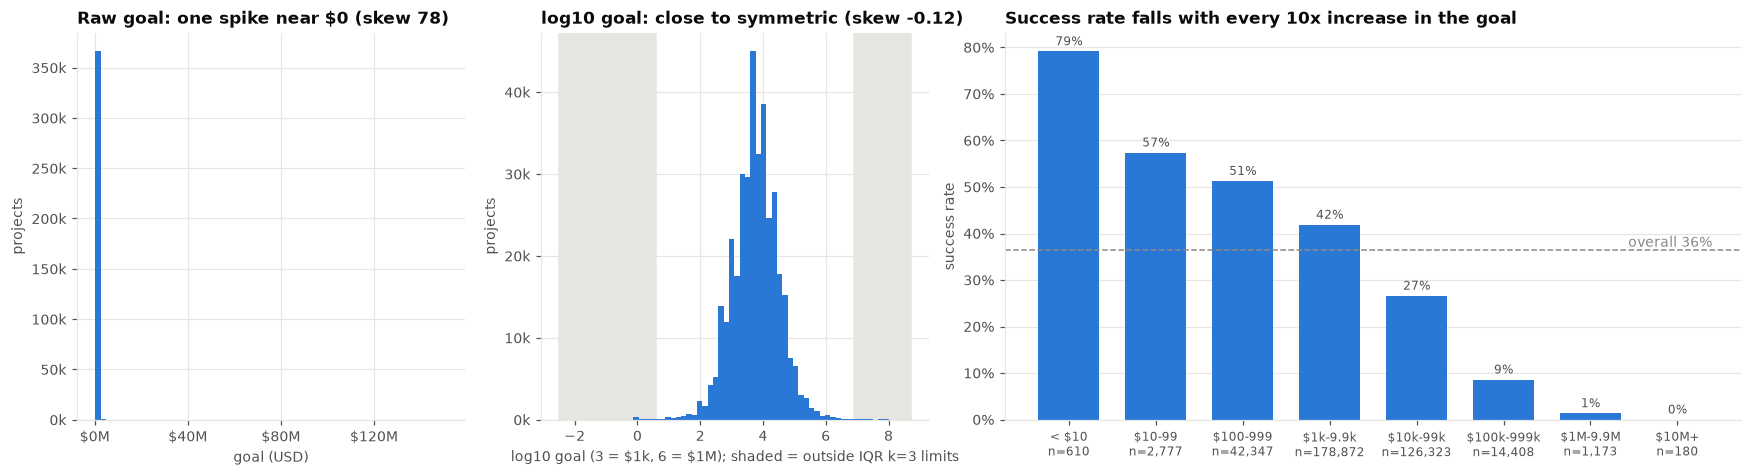

In [26]:
# 16 (chart). Raw goal vs log goal, and success rate by goal size
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.9]})

axes[0].hist(df["usd_goal_real"], bins=60, color=BLUE)
axes[0].set_title(f"Raw goal: one spike near $0 (skew {skew(df['usd_goal_real']):.0f})")
axes[0].set_xlabel("goal (USD)")
axes[0].set_ylabel("projects")
axes[0].xaxis.set_major_locator(plt.MaxNLocator(5))
axes[0].xaxis.set_major_formatter(lambda x, _: f"${x / 1e6:.0f}M")

axes[1].hist(df["log10_goal_usd"], bins=60, color=BLUE)
axes[1].axvspan(axes[1].get_xlim()[0], lo, color=GRID, zorder=0)
axes[1].axvspan(hi, axes[1].get_xlim()[1], color=GRID, zorder=0)
axes[1].set_title(f"log10 goal: close to symmetric (skew {skew(df['log10_goal_usd']):.2f})")
axes[1].set_xlabel("log10 goal (3 = $1k, 6 = $1M); shaded = outside IQR k=3 limits")
axes[1].set_ylabel("projects")
for ax in axes[:2]:
    ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.0f}k")

goal_bin = np.floor(df["log10_goal_usd"]).clip(0, 7)            # < $10 and $10M+ grouped (very few projects)
by_goal = df.groupby(goal_bin)["target_state"].agg(["mean", "size"])
names = {0: "< $10", 1: "$10-99", 2: "$100-999", 3: "$1k-9.9k", 4: "$10k-99k", 5: "$100k-999k", 6: "$1M-9.9M", 7: "$10M+"}
labels = [f"{names[int(b)]}\nn={n:,}" for b, n in by_goal["size"].items()]
bars = axes[2].bar(labels, by_goal["mean"], color=BLUE, width=0.7)
axes[2].bar_label(bars, labels=[f"{m:.0%}" for m in by_goal["mean"]], padding=2, color=INK, fontsize=8)
axes[2].axhline(df["target_state"].mean(), color=MUTED, linestyle="--", linewidth=1)
axes[2].text(len(labels) - 0.6, df["target_state"].mean(), f"overall {df['target_state'].mean():.0%}", color=MUTED, ha="right", va="bottom")
axes[2].set_title("Success rate falls with every 10x increase in the goal")
axes[2].set_ylabel("success rate")
axes[2].yaxis.set_major_formatter(PercentFormatter(1))
axes[2].tick_params(axis="x", labelsize=8)
axes[2].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

### Goal: what the results tell us

- **The log fixes the skew.** The raw goal is extremely skewed (skewness 78.1: most goals are a few thousand dollars, a few reach $100M). After log10 it is almost symmetric (-0.12).
- **Hardly any outliers on the log scale.** Even with a wide IQR rule (k = 3), only 617 projects (~0.17%) fall outside the limits of $3.91 and $8.2M.
- **A clear, smooth pattern: the bigger the goal, the lower the success rate.**

| Goal range | Projects | Success rate |
|---|---|---|
| under $10 | 610 | ~79% |
| $100 – $999 | 42,347 | 51% |
| $1k – $9.9k | 178,872 | 42% |
| $10k – $99k | 126,323 | 27% |
| $100k – $999k | 14,408 | 8.6% |
| $10M+ | 180 | 0% |

- **The extremes carry signal, they are not errors.** Tiny goals usually succeed and $10M+ goals never do, so capping them would hide the cases where the goal predicts best.

**Decision:** use `log10_goal_usd`, no capping. The goal is likely one of the strongest features for the model.

In [27]:
# 17. Duration: why no capping and no log
# Duration is bounded by Kickstarter's own rules (max 60 days; 90 before 2011), so there are no real outliers.
# Success depends on the exact value (30 days, the default: 32%; 60 days: 19%; under 30 days: ~45-50%), which
# capping would blur -> left as it is.
print(df["duration_days"].describe())
print(df.groupby(pd.cut(df["duration_days"], [0, 9, 19, 29, 30, 44, 59, 60, 92]), observed=False)["target_state"]
      .agg(["mean", "size"]).round(3))

count    366690.000000
mean         34.174965
std          12.791811
min           1.000000
25%          30.000000
50%          30.000000
75%          37.000000
max          92.000000
Name: duration_days, dtype: float64
                mean    size
duration_days               
(0, 9]         0.465    4374
(9, 19]        0.502   19999
(19, 29]       0.491   43213
(29, 30]       0.322  164033
(30, 44]       0.450   64877
(44, 59]       0.313   32618
(59, 60]       0.193   32148
(60, 92]       0.344    5428


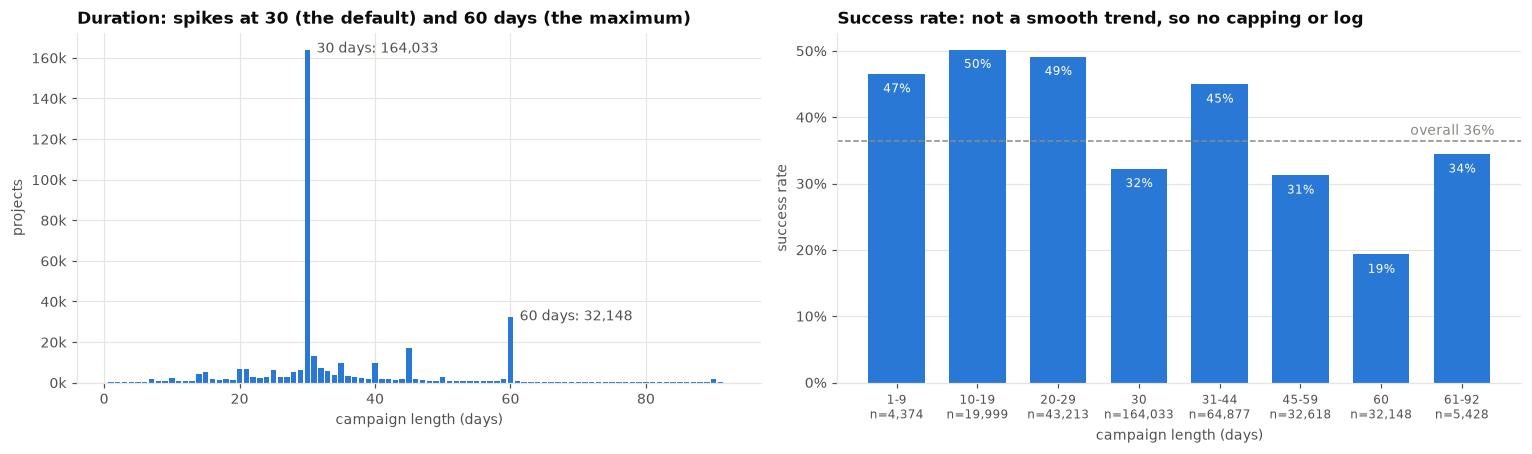

In [28]:
# 17 (chart). Duration: most projects use 30 days, and success depends on the exact value
from matplotlib.ticker import PercentFormatter

dur_bins = pd.cut(df["duration_days"], [0, 9, 19, 29, 30, 44, 59, 60, 92])
by_dur = df.groupby(dur_bins, observed=False)["target_state"].agg(["mean", "size"])
dur_labels = ["1-9", "10-19", "20-29", "30", "31-44", "45-59", "60", "61-92"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
counts = df["duration_days"].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=BLUE, width=0.8)
for d in (30, 60):
    axes[0].annotate(f"{d} days: {counts[d]:,}", (d, counts[d]), xytext=(6, -2), textcoords="offset points", color=INK)
axes[0].set_title("Duration: spikes at 30 (the default) and 60 days (the maximum)")
axes[0].set_xlabel("campaign length (days)")
axes[0].set_ylabel("projects")
axes[0].yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.0f}k")

bars = axes[1].bar([f"{l}\nn={n:,}" for l, n in zip(dur_labels, by_dur["size"])], by_dur["mean"], color=BLUE, width=0.7)
axes[1].bar_label(bars, labels=[f"{m:.0%}" for m in by_dur["mean"]], padding=-14, color="white", fontsize=8)
axes[1].axhline(df["target_state"].mean(), color=MUTED, linestyle="--", linewidth=1)
axes[1].text(len(dur_labels) - 0.6, df["target_state"].mean() + 0.004, f"overall {df['target_state'].mean():.0%}", color=MUTED, ha="right", va="bottom")
axes[1].set_title("Success rate: not a smooth trend, so no capping or log")
axes[1].set_xlabel("campaign length (days)")
axes[1].set_ylabel("success rate")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].tick_params(axis="x", labelsize=8)
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

In [29]:
# 18. Launch weekday and hour vs success
print(df.groupby("launch_weekday", observed=False)["target_state"].mean().round(3))
print(df.groupby("launch_hour")["target_state"].mean().round(3))

launch_weekday
Monday       0.366
Tuesday      0.384
Wednesday    0.367
Thursday     0.363
Friday       0.351
Saturday     0.337
Sunday       0.364
Name: target_state, dtype: float64
launch_hour
0     0.332
1     0.342
2     0.343
3     0.341
4     0.348
5     0.356
6     0.379
7     0.357
8     0.355
9     0.378
10    0.353
11    0.357
12    0.387
13    0.420
14    0.443
15    0.444
16    0.414
17    0.388
18    0.378
19    0.364
20    0.348
21    0.343
22    0.333
23    0.336
Name: target_state, dtype: float64


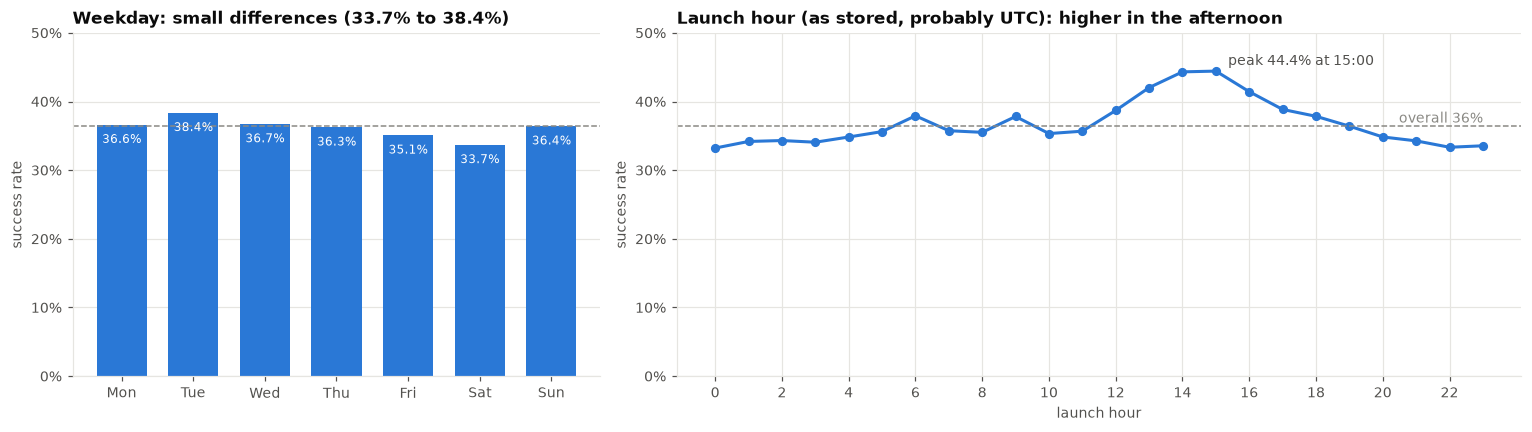

In [30]:
# 18 (chart). Success rate by launch weekday and launch hour
from matplotlib.ticker import PercentFormatter

overall = df["target_state"].mean()
by_day = df.groupby("launch_weekday", observed=False)["target_state"].mean()
by_hour = df.groupby("launch_hour")["target_state"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.6]})
bars = axes[0].bar([d[:3] for d in by_day.index], by_day.values, color=BLUE, width=0.7)
axes[0].bar_label(bars, labels=[f"{m:.1%}" for m in by_day], label_type="edge", padding=-14, color="white", fontsize=8)
axes[0].set_title(f"Weekday: small differences ({by_day.min():.1%} to {by_day.max():.1%})")
axes[0].set_ylim(0, 0.5)
axes[0].grid(axis="x", visible=False)

axes[1].plot(by_hour.index, by_hour.values, color=BLUE, linewidth=2, marker="o", markersize=5)
peak = by_hour.idxmax()
axes[1].annotate(f"peak {by_hour.max():.1%} at {peak}:00", (peak, by_hour.max()), xytext=(8, 4), textcoords="offset points", color=INK)
axes[1].set_title("Launch hour (as stored, probably UTC): higher in the afternoon")
axes[1].set_xlabel("launch hour")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_ylim(0, 0.5)

for ax in axes:
    ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_ylabel("success rate")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[1].text(23, overall, f"overall {overall:.0%}", color=MUTED, ha="right", va="bottom")
fig.tight_layout()
plt.show()

In [31]:
# 19. Categorical features: rare values (< 0.5% of rows) -> "Other"
# main_category is dropped: category is more detailed and more informative (success rates 7%-82% vs 24%-65%).
for col in ["category", "country"]:
    share = df[col].value_counts(normalize=True)
    rare = share[share < RARE_SHARE].index
    df[col] = df[col].where(~df[col].isin(rare), "Other")
    print(f"{col}: {len(rare)} rare values grouped into 'Other' -> {df[col].nunique()} values")

category: 106 rare values grouped into 'Other' -> 54 values
country: 13 rare values grouped into 'Other' -> 10 values


In [32]:
# 20. Build the model table: drop excluded columns, one-hot encode the categorical features (if ONE_HOT_ENCODE)
# ONE_HOT_ENCODE = True: each categorical feature becomes 0/1 columns (e.g. launch_hour_0 ... launch_hour_23).
# ONE_HOT_ENCODE = False: each stays one column (weekday, country, category as text; month, day, hour as numbers).
features_num = ["log10_goal_usd", "name_length", "duration_days", "launch_year"]
features_cat = ["launch_weekday", "launch_month", "launch_day", "launch_hour", "country", "category"]
model = df[["target_state"] + features_num + features_cat + ["split_group", "state"]]
if ONE_HOT_ENCODE:
    model = pd.get_dummies(model, columns=features_cat, dtype=int)
    cat_cols = [c for c in model.columns if c.startswith(tuple(f + "_" for f in features_cat))]
else:
    model = model.assign(launch_weekday=model["launch_weekday"].astype(str))   # plain text, as when read back from the CSV
    cat_cols = features_cat
# original_state = the state before it became target_state (failed / successful / canceled): for comparisons only, NEVER a feature
model = model.rename(columns={"state": "original_state"})
model = model[["target_state"] + features_num + cat_cols + ["split_group", "original_state"]].reset_index(drop=True)
print(model.shape)

(366690, 13)


In [33]:
# 21. Final checks: missing values, coincidental duplicates, one-hot sanity
# Rows that are identical in every feature are different projects that coincide (same category, country, launch day,
# round goal, 30 days, same name length); they are real projects and are kept.
print("missing values left:", int(model.isna().sum().sum()))
feat_cols = [c for c in model.columns if c not in ("target_state", "split_group", "original_state")]
print("rows identical in every feature:", int(model.duplicated(feat_cols, keep=False).sum()),
      "| from the same project family:",
      int(model[model.duplicated(feat_cols, keep=False)].groupby(feat_cols)["split_group"].nunique().eq(1).sum()))
if ONE_HOT_ENCODE:
    for f in features_cat:
        cols = [c for c in model.columns if c.startswith(f + "_")]
        print(f"{f}: {len(cols)} one-hot columns, exactly one 1 per row:", bool((model[cols].sum(axis=1) == 1).all()))
else:
    print("categorical features kept as one column each (distinct values):", model[features_cat].nunique().to_dict())

missing values left: 0
rows identical in every feature: 68 | from the same project family: 0
categorical features kept as one column each (distinct values): {'launch_weekday': 7, 'launch_month': 12, 'launch_day': 31, 'launch_hour': 24, 'country': 10, 'category': 54}


### `split_group`: one ID per project family

**What it is:** every row gets the number of its *project family*. Rows with the same cleaned name in the same category (names of at least 6 characters) are attempts at the same project and share the same number, e.g. "Smart Wallet (Canceled)" and a later "Smart Wallet", both in *Product Design*.

**Example.** The number itself is just a label (families are numbered 0, 1, 2, ... in the order of their first launch, so older projects have smaller numbers). What matters is *which rows share the same number*:

| name | category | launched | goal (USD) | state | split_group |
|---|---|---|---|---|---|
| The Songs of Adelaide & Abullah | Poetry (now "Other") | 2015-08-11 | 1,534 | failed | **237706** |
| ROUNDEYE: For Love (Canceled) | Comics | 2010-12-01 | 60,000 | canceled | **10583** |
| ROUNDEYE: For Love | Comics | 2011-01-20 | 10,000 | successful | **10583** |

- The first project in the file has `split_group` **237706**. No other row has 237706, so this project was posted only once. That is the case for almost every project.
- "ROUNDEYE: For Love" was canceled with a $60,000 goal and relaunched seven weeks later with $10,000, and then succeeded. Both rows get **10583**, so a grouped split always puts them on the same side (both in train or both in test).

**Where it comes from:**
- Re-posted **within 7 days** → the first posting was a draft: only the last one is kept (687 rows removed, section 12b).
- Re-posted **later** → a real new attempt: both rows are kept, with the same `split_group`.

In the final data there are 364,547 families; **2,019 have more than one row**.

**Why it matters: leakage between train and test.** With a random split, attempt 1 of a project can land in training and attempt 2 in test. They share almost every feature (name length, category, country, goal), so the model would partly *recognise* the project instead of predicting it, and the test score would be too optimistic. Use a grouped split so all attempts stay on the same side:

```python
from sklearn.model_selection import GroupShuffleSplit   # or GroupKFold / StratifiedGroupKFold for CV
X = final.drop(columns=["target_state", "split_group", "original_state"])
y = final["target_state"]
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                           .split(X, y, groups=final["split_group"]))
```

**Never use it as a feature:** the number itself means nothing, it is only a label (like a customer ID).

The next cell checks whether the relaunched projects should be kept at all.

                 mean    size
single project  0.366  362528
1st of several  0.112    2019
2nd attempt     0.349    2019
3rd+ attempt    0.298     124
                             rows success rate AUC, own test rows         AUC, single projects        
                             mean         mean               mean     std                 mean     std
version                                                                                               
keep all attempts        366690.0       0.3645             0.7587  0.0007               0.7589  0.0007
keep last attempt only   364547.0       0.3659             0.7586  0.0008               0.7587  0.0008
keep first attempt only  364547.0       0.3646             0.7587  0.0007               0.7588  0.0007


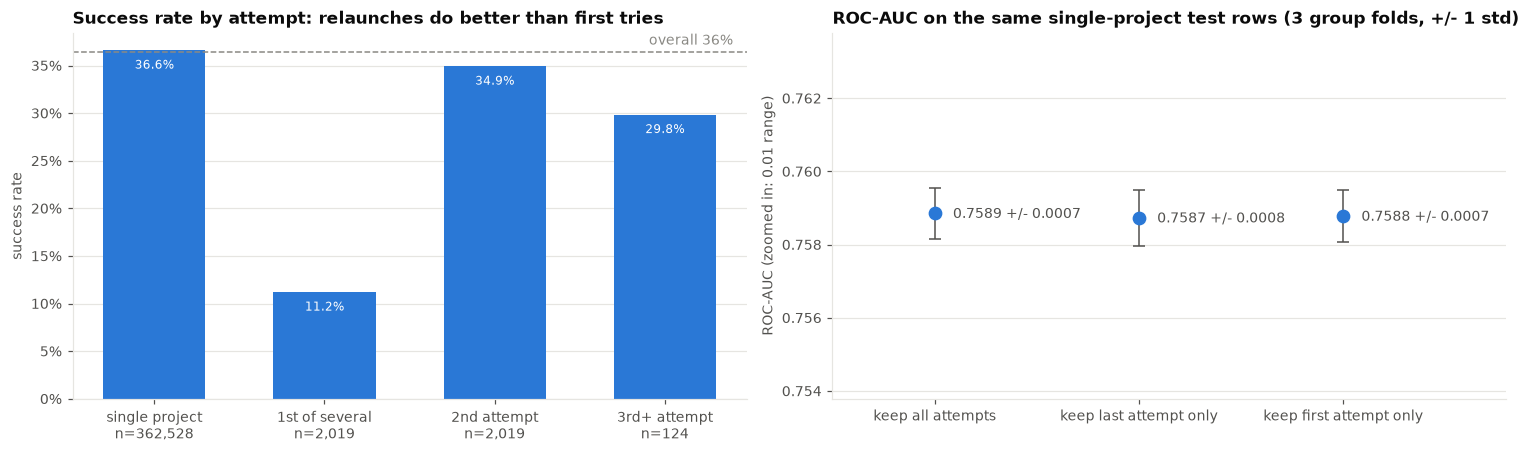

In [34]:
# 21b. Relaunched projects: keep them, or keep only one attempt per project?
# Same data, three versions: all attempts (current) / only the last attempt / only the first attempt per project family.
# Scored with the same group-based folds (no family in both train and test), on all test rows and on the test rows of
# single-attempt projects (identical in every version, so a fair comparison).
# Result: first attempts of relaunched projects rarely succeed (11%), the next attempt does almost as well as a normal
# project (35%). The three versions score the same (AUC 0.7562-0.7564 one-hot, 0.7587-0.7589 without; differences
# smaller than the fold-to-fold noise)
# -> keep all attempts (more data, nothing lost) and use split_group for every train/test split.
from matplotlib.ticker import PercentFormatter

order = df.sort_values("launched_dt").groupby("split_group").cumcount()      # 0 = first attempt
attempt = order.reindex(df.index).to_numpy() + 1                               # same row order as model
n_attempts = model["split_group"].map(model["split_group"].value_counts()).to_numpy()
kind = np.select([n_attempts == 1, attempt == 1, attempt == 2], ["single project", "1st of several", "2nd attempt"],
                 "3rd+ attempt")
rate = model.groupby(kind)["target_state"].agg(["mean", "size"]).reindex(
    ["single project", "1st of several", "2nd attempt", "3rd+ attempt"])
print(rate.round(3))

versions = {"keep all attempts": np.ones(len(model), bool),
            "keep last attempt only": attempt == n_attempts,
            "keep first attempt only": attempt == 1}
if RUN_MODEL_CHECKS:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import GroupKFold

    X, y, groups = model[feat_cols], model["target_state"], model["split_group"]
    if not ONE_HOT_ENCODE:                                  # text columns -> pandas category, which the model reads natively
        X = X.astype({c: "category" for c in ["launch_weekday", "country", "category"]})
    single = n_attempts == 1
    rows = []
    for fold, (tr, te) in enumerate(GroupKFold(n_splits=3, shuffle=True, random_state=0).split(X, y, groups)):
        te_s = te[single[te]]
        for name, keep in versions.items():
            tr_v, te_v = tr[keep[tr]], te[keep[te]]
            m = HistGradientBoostingClassifier(max_iter=200, categorical_features="from_dtype", random_state=0).fit(X.iloc[tr_v], y.iloc[tr_v])
            rows.append({"version": name, "rows": keep.sum(), "success rate": y[keep].mean(),
                         "AUC, own test rows": roc_auc_score(y.iloc[te_v], m.predict_proba(X.iloc[te_v])[:, 1]),
                         "AUC, single projects": roc_auc_score(y.iloc[te_s], m.predict_proba(X.iloc[te_s])[:, 1])})
    scores = pd.DataFrame(rows).groupby("version", sort=False).agg(["mean", "std"])
    scores = scores.drop(columns=[("rows", "std"), ("success rate", "std")])
    print(scores.round(4).to_string())

fig, axes = plt.subplots(1, 2 if RUN_MODEL_CHECKS else 1, figsize=(14, 4.2), squeeze=False)
ax = axes[0, 0]
bars = ax.bar([f"{k}\nn={n:,}" for k, n in rate["size"].items()], rate["mean"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{m:.1%}" for m in rate["mean"]], padding=-14, color="white", fontsize=8)
ax.axhline(model["target_state"].mean(), color=MUTED, linestyle="--", linewidth=1)
ax.text(3.4, model["target_state"].mean() + 0.004, f"overall {model['target_state'].mean():.0%}", color=MUTED, ha="right", va="bottom")
ax.set_title("Success rate by attempt: relaunches do better than first tries")
ax.set_ylabel("success rate")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
if RUN_MODEL_CHECKS:
    ax = axes[0, 1]
    auc, err = scores[("AUC, single projects", "mean")], scores[("AUC, single projects", "std")]
    ax.errorbar(range(len(auc)), auc, yerr=err, fmt="o", color=BLUE, markersize=8, ecolor=INK, capsize=4, linewidth=1)
    for i, (a, e) in enumerate(zip(auc, err)):
        ax.annotate(f"{a:.4f} +/- {e:.4f}", (i, a), xytext=(12, -3), textcoords="offset points", color=INK)
    ax.set_xticks(range(len(auc)), auc.index)
    ax.set_xlim(-0.5, len(auc) - 0.2)
    ax.set_ylim(auc.mean() - 0.005, auc.mean() + 0.005)                       # a 0.01-wide window: differences are tiny
    ax.set_title("ROC-AUC on the same single-project test rows (3 group folds, +/- 1 std)")
    ax.set_ylabel("ROC-AUC (zoomed in: 0.01 range)")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

### Relaunched projects: what the results say

The first try of a relaunched project rarely succeeds (11%), while the next attempt does almost as well as a normal project (35% vs 37%): creators pull a weak campaign and come back with a better one. Keeping all attempts, only the last, or only the first gives the same ROC-AUC (0.7562-0.7564 with `ONE_HOT_ENCODE = True`, 0.7587-0.7589 with `False`; within each setting the differences are smaller than the fold-to-fold noise), because relaunches are only ~1% of the rows.

**Decision:** keep all attempts (real projects with real outcomes, nothing lost) and always split train/test by `split_group`, so no project family ends up on both sides.

In [35]:
# 21c. New feature: goal_vs_category = how ambitious the goal is for its category
# log10 goal minus the median log10 goal of the project's category: 0 = a typical goal for the category, +1 = 10x the
# typical goal, -1 = a tenth of it (a $20k goal is large for poetry but small for hardware). The median uses only the
# goals, never the outcome, so there is no target leakage. Success falls steadily as the goal gets more ambitious for
# its category (printed below).
category_median_goal = df.groupby("category")["log10_goal_usd"].transform("median")
model.insert(1 + len(features_num), "goal_vs_category", (df["log10_goal_usd"] - category_median_goal).to_numpy())
features_num = features_num + ["goal_vs_category"]
print(model["goal_vs_category"].describe().round(2))
print(model.groupby(pd.qcut(model["goal_vs_category"], 5))["target_state"].mean().round(3))

count    366690.00
mean         -0.02
std           0.69
min          -5.70
25%          -0.40
50%           0.00
75%           0.40
max           4.79
Name: goal_vs_category, dtype: float64
goal_vs_category
(-5.7, -0.534]      0.478
(-0.534, -0.143]    0.428
(-0.143, 0.16]      0.384
(0.16, 0.501]       0.333
(0.501, 4.786]      0.200
Name: target_state, dtype: float64


In [36]:
# 22. Save and summary of every row removed
model.to_csv(OUTPUT, index=False)
print(pd.DataFrame(decision_log, columns=["step", "rows removed", "rows left"]).to_string(index=False))
print(f"\nSaved {OUTPUT}: {model.shape[0]:,} rows x {model.shape[1]} columns, success rate {model['target_state'].mean():.1%}")
print(f"Columns: target_state | {len(features_num)} numeric features | {len(features_cat)} categorical features "
      f"({'one-hot' if ONE_HOT_ENCODE else 'one column each'}) | split_group (NOT a feature: "
      "use it for GroupShuffleSplit / GroupKFold) | original_state (NOT a feature: it is the outcome)")

                                                                           step  rows removed  rows left
                                                       live / undefined removed          6361     372300
      rows with missing values removed (name, country 'N,0"', launch date 1970)           245     372055
                              canceled projects with >= 50% of the goal removed          2055     370000
                                                     suspended projects removed          1842     368158
                            re-posted within 7 days removed (last posting kept)           687     367471
joke / test projects removed (potato_salad_wave, test_project, silly_tiny_goal)           781     366690

Saved data/kickstarter_final.csv: 366,690 rows x 14 columns, success rate 36.4%
Columns: target_state | 5 numeric features | 6 categorical features (one column each) | split_group (NOT a feature: use it for GroupShuffleSplit / GroupKFold) | original_state (NOT a f

In [37]:
# 23. Quick overview of the final dataset (read back from the saved file)
final = pd.read_csv(OUTPUT)
num_cols = features_num
groups = {f: [c for c in final.columns if c.startswith(f + "_")] for f in features_cat}      # one-hot columns per feature

print(f"{OUTPUT}: {final.shape[0]:,} rows x {final.shape[1]} columns, {final.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
try:                                    # int32 -> int64 and tiny float rounding in the CSV are not real differences
    pd.testing.assert_frame_equal(final, model, check_dtype=False)
    print("same as the model table in memory: True")
except AssertionError as e:
    print("same as the model table in memory: False ->", str(e).splitlines()[0])
cat_desc = (" | ".join(f"{len(v)} {k}" for k, v in groups.items()) if ONE_HOT_ENCODE
            else f"{len(features_cat)} categorical (one column each)")
print(f"\ncolumns: 1 target_state | {len(num_cols)} numeric | {cat_desc} | split_group, original_state (not features)")
print("column types:", final.dtypes.value_counts().to_dict())
print("missing values:", int(final.isna().sum().sum()))
print(f"\ntarget_state: {final['target_state'].value_counts().to_dict()} -> success rate {final['target_state'].mean():.1%}")
print(pd.crosstab(final["original_state"], final["target_state"], margins=True))
print(f"split_group: {final['split_group'].nunique():,} project families "
      f"({(final['split_group'].value_counts() > 1).sum():,} with more than one row)")

print("\nnumeric features:")
print(final[num_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(2))
print("\nmost common values per categorical feature (share of rows):")
for f in features_cat:
    if ONE_HOT_ENCODE:
        top = final[groups[f]].mean().sort_values(ascending=False).head(5)
        top.index = top.index.str.removeprefix(f + "_")
    else:
        top = final[f].value_counts(normalize=True).head(5)
    print(f"  {f}: " + ", ".join(f"{v} {s:.1%}" for v, s in top.items()))
final.head()

data/kickstarter_final.csv: 366,690 rows x 14 columns, 110 MB in memory
same as the model table in memory: True

columns: 1 target_state | 5 numeric | 6 categorical (one column each) | split_group, original_state (not features)
column types: {dtype('int64'): 8, <StringDtype(storage='python', na_value=nan)>: 4, dtype('float64'): 2}
missing values: 0

target_state: {0: 233038, 1: 133652} -> success rate 36.4%
target_state         0       1     All
original_state                        
canceled         35962       0   35962
failed          197076       0  197076
successful           0  133652  133652
All             233038  133652  366690
split_group: 364,547 project families (2,019 with more than one row)

numeric features:
                     mean    std     min      50%      max
log10_goal_usd       3.76   0.73    -2.0     3.74     8.18
name_length         34.17  16.02     0.0    33.00    85.00
duration_days       34.17  12.79     1.0    30.00    92.00
launch_year       2014.21   1.9

,target_state,log10_goal_usd,name_length,duration_days,launch_year,goal_vs_category,launch_weekday,launch_month,launch_day,launch_hour,country,category,split_group,original_state
0,0,3.185811,31,59,2015,-0.513159,Tuesday,8,11,12,GB,Other,237706,failed
1,0,4.477121,45,60,2017,0.477121,Saturday,9,2,4,US,Narrative Film,352360,failed
2,0,4.653213,14,45,2013,0.653213,Saturday,1,12,0,US,Narrative Film,79678,failed
3,0,3.698970,49,30,2012,0.000000,Saturday,3,17,3,US,Music,46115,failed
4,0,4.290035,58,56,2015,0.414973,Saturday,7,4,8,US,Film & Video,230745,canceled
